# QLoRA DialogSum — final corrected Colab notebook

This notebook contains the completed QLoRA training and validation run, saved outputs, and answers updated to match those outputs. QLoRA took 13.2 minutes; validation ROUGE-L was 37.2 on 60 examples. The Q4 baseline-display cell has been changed to show five examples and must be rerun to refresh that cell output. A Colab T4 GPU and Internet are required for a fresh full run.

In [1]:
import importlib.util
import os
import subprocess
import sys

PLATFORM = "colab"
required = ["transformers","peft","datasets","bitsandbytes","accelerate","rouge-score"]
modules = {"scikit-learn": "sklearn", "rouge-score": "rouge_score"}
missing = [pkg for pkg in required if importlib.util.find_spec(modules.get(pkg, pkg.replace("-", "_"))) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Platform:", PLATFORM, "| missing packages installed:", missing)

Platform: colab | missing packages installed: ['bitsandbytes', 'rouge-score']


# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one- or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/peft/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Google Colab with a T4 GPU runtime** and internet enabled. Exercises 1 and 2 also run on a CPU; model loading, training, and generation require a compatible GPU.
- The first setup cell installs missing transformers, peft, datasets, bitsandbytes, accelerate, and rouge_score packages. Restart the runtime only if Colab asks for it.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Files.** Training writes only the LoRA adapter, to `/content/qlora_dialogsum/adapter/` (or `/content/qlora_dialogsum/adapter/` elsewhere). Rerunning overwrites it. The model and dataset go to the Hugging Face cache.

**How to work:** run the cells in order. Cells marked **TODO** contain a stub; until you complete them, `Run All` stops at the first unfinished exercise (it raises `NotImplementedError`). Each exercise is followed by a check cell.

**Marks (25):** Ex. 1 — 2 · Ex. 2 — 4 · Ex. 3 — 2 · Ex. 4 — 3 · Ex. 5 — 4 · Ex. 6 — 3 · Ex. 7 — 4 · Ex. 8 — 1 · reflection — 2.

## Setup

The first code cell checks for the required packages and installs only missing ones. Keep internet enabled during package, model, and dataset downloads. If Colab requests a runtime restart after installation, restart and run all cells again from the top.

In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000           # training dialogues (of 12,460); more data trains longer
N_EVAL = 60              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")


torch 2.14.1+cu130 | transformers 5.22.1
GPU: Tesla T4


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/peft/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [3]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales


In [4]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return {"full FT": GB, "LoRA": GB, "QLoRA": GB}, before activations."""
    full_ft = 16 * n_total
    lora = 2 * (n_total - n_lora) + 16 * n_lora
    qlora = NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora
    return {"full FT": full_ft / GB, "LoRA": lora / GB, "QLoRA": qlora / GB}


In [5]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.35) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")


full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.35 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Answer:** Before activations, the estimates are 24.70 GB for full fine-tuning, 3.35 GB for LoRA, and 1.91 GB for QLoRA; LoRA and QLoRA fit within 16 GB, while full fine-tuning does not. QLoRA is useful practice because it reduces frozen-weight memory and makes the method scale to larger models; quantization can add setup/compute overhead and some numerical error when plain LoRA already fits. Scaling the QLoRA estimate by five gives roughly 9.55 GB before activations.

## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [6]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])


README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

... (5 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1

--- reference summary ---
Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.


**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [7]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))


<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [8]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    input_ids = prompt_ids + answer_ids
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids),
            "labels": [-100] * len(prompt_ids) + answer_ids}


In [9]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")


347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [10]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])


training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Answer:** Without masking the prompt labels, the model would spend loss on reproducing the instruction and dialogue as well as the summary. That wastes training capacity because the objective is to learn summary tokens, not copy the input; the cell’s token counts show how much of each example is prompt versus scored answer. `<|im_end|>` teaches the model where its response stops; without it generation may continue into extra text or fail to stop at the intended boundary. Dropping over-length examples preserves complete prompts and targets, whereas truncation can cut off the dialogue or target and create malformed supervision.

## Exercise 3 — Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [11]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward needs a GPU (Kaggle: Settings -> Accelerator -> GPU T4)"
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_use_double_quant=True,
                                bnb_4bit_compute_dtype=torch.float16)
model = AutoModelForCausalLM.from_pretrained(CKPT, quantization_config=bnb_config,
                                             torch_dtype=torch.float16, device_map={"": 0})


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [12]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb < 2.0, "a 4-bit 1.5B model should need well under 2 GB"
print("Exercise 3 checks passed.")


4-bit linear layers: 196 | GPU memory after loading: 1.15 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Answer:** The measured memory is expected to exceed the 1.14 GB weight estimate because CUDA context, quantization metadata, non-quantized layers, buffers, and allocator overhead also consume memory. FP16 is broadly supported on T4 GPUs and has lower memory use than FP32. On an A100, BF16 is generally a good compute choice because it has a wider exponent range and is supported by the hardware.

## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [ ]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:5]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)


**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [14]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)

def rouge(preds, refs):
    totals = {key: 0.0 for key in ROUGE_KEYS}
    for pred, ref in zip(preds, refs):
        scores = scorer.score(ref, pred)
        for key in ROUGE_KEYS:
            totals[key] += scores[key].fmeasure
    n = max(len(preds), 1)
    return {key: 100 * value / n for key, value in totals.items()}


In [15]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")


{'rouge1': 32.1, 'rouge2': 8.4, 'rougeL': 23.0} | mean words: model 33, reference 22
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

**Answer:** The baseline averaged 33 words while references averaged 22, so it tended to be more verbose. It also paraphrased freely and often used names or narrative descriptions instead of the references’ speaker-label style. In the saved hotel example, the model mentions internet access and a minibar, but misses the reference’s tip policy and advance-reservation advice. In the Green Peace example it describes Peter’s protests but omits some interview context. These wording and speaker-label differences can lower ROUGE despite conveying supported information; omissions and unsupported details can also be genuine quality problems. The Q4 code now prints five examples; review all five after rerunning that cell.

## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

In [16]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
lora_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear",
                         task_type="CAUSAL_LM")
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(OUT / "trainer"), per_device_train_batch_size=4,
    gradient_accumulation_steps=4, num_train_epochs=1, learning_rate=2e-4,
    lr_scheduler_type="cosine", warmup_steps=10, fp16=True, bf16=False,
    optim="paged_adamw_8bit", gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False}, logging_steps=10,
    save_strategy="no", report_to="none", remove_unused_columns=False, seed=SEED)


In [17]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
assert args.fp16 and not args.bf16 and "paged" in str(args.optim).lower()
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")


trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [18]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")


Step,Training Loss
10,1.296502
20,1.095569
30,1.074806
40,1.031997
50,0.981979
60,1.006680
70,1.043178
80,0.971106
90,0.933448
100,1.024990


training time: 13.2 min | peak GPU memory: 6.37 GB (Exercise 1 estimate before activations: 1.91 GB)


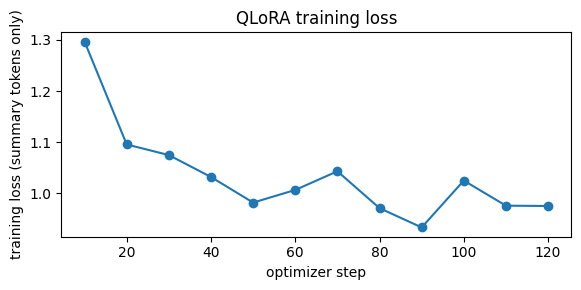

Exercise 5 checks passed.


In [19]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
assert losses[-1] < losses[0], "the loss should go down over the epoch"
print("Exercise 5 checks passed.")


**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

**Answer:** The recorded run took 13.2 minutes and reached about 6.37 GB peak GPU memory. Peak usage exceeds the 1.91 GB weight estimate because training also needs activations, gradients for adapters, optimizer states, temporary workspaces, and runtime overhead. The small per-device batch, gradient accumulation, gradient checkpointing, 4-bit frozen weights, and 8-bit paged optimizer limit that peak. Lower training loss only shows better fit to the sampled training examples; validation performance, factuality, and independent evaluation are needed to establish better summaries.

## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [20]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")


generated 60 summaries in 56 s


In [21]:
tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(scorer.score(ref, tuned)["rougeL"].fmeasure > scorer.score(ref, base)["rougeL"].fmeasure
           for tuned, base, ref in zip(tuned_preds, base_preds, eval_refs))


In [22]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")


               rouge1   rouge2   rougeL   words
base             32.1      8.4     23.0      33
QLoRA            45.4     18.6     37.2      22
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

**Answer:** In this run, ROUGE-1/2/L changed from 32.1/8.4/23.0 for the base model to 45.4/18.6/37.2 for QLoRA. ROUGE-L was higher on 54 of 60 validation dialogues. Average summary length changed from 33 words to 22, matching the 22-word reference average. Reference-like concise style and speaker-label patterns can increase n-gram overlap without proving better factual coverage. With only 60 validation examples and one training run, this is preliminary evidence; a larger untouched test set, multiple seeds, confidence intervals, and independent blinded human ratings are needed before claiming a reliable improvement.

## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [23]:
HUMAN_IDS = list(range(6))
rating_rng = random.Random(SEED + 17)
order = {index: rating_rng.choice(["base", "QLoRA"]) for index in HUMAN_IDS}
for i in HUMAN_IDS:
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")


=================== example 0 ===================
#Person1#: Did you enjoy your weekend at the highland hotel? I heard it's and excellent place to stay and has good facilities.
#Person2#: I had a wonderful time. The rooms are not very big, but they are well furnished. The restaurant is excellent and reasonably priced. There's a sauna and a Jacuzzi.
#Person1#: Do they have a swimming pool?
#Person2#: No, they don't. they have a beauty parlor, but I didn't go there.
#Person1#: What's the service like?
#Person2#: It's very good. Check in and check out at the reception only took a few minutes. The wait staff is very good. A waiter recommended their baked fish, which tasted wonderful. The hotel was quite full, so I'd suggest making a reservation if you intend to go there. The hotel offers a discount at the weekends.
#Person1#: It sounds perfect. Did you have any complaints at all?
#Person2#: There was a problem with the internet access, so I couldn't check my email, but I didn't complain ab

Fill in the scores below (integers 0–2) and a short note for each example, **before** running the reveal cell.

In [24]:
print("Assistant assessment selected; these are not human ratings.")
ratings = {
    0: {"A_faithful": 1, "A_coverage": 2, "B_faithful": 2, "B_coverage": 1, "note": "Assistant assessment: both summaries are mostly supported; A includes more details, B omits tip policy and reservation advice."},
    1: {"A_faithful": 2, "A_coverage": 2, "B_faithful": 2, "B_coverage": 2, "note": "Assistant assessment: both capture Peter’s role and anti-nuclear campaigns; neither has a material unsupported claim."},
    2: {"A_faithful": 2, "A_coverage": 1, "B_faithful": 2, "B_coverage": 2, "note": "Assistant assessment: both are faithful; A is concise and B includes how the pair first met."},
    3: {"A_faithful": 1, "A_coverage": 2, "B_faithful": 2, "B_coverage": 1, "note": "Assistant assessment: A incorrectly says Lucy decided to search alone; B is supported but omits Rusty’s discovery and reunion."},
    4: {"A_faithful": 1, "A_coverage": 2, "B_faithful": 2, "B_coverage": 1, "note": "Assistant assessment: A misattributes who asked Adam for the tour; B is accurate but leaves out library and school details."},
    5: {"A_faithful": 2, "A_coverage": 2, "B_faithful": 2, "B_coverage": 2, "note": "Assistant assessment: both summarize the supermarket and yard-work jobs and mention their downsides."}
}


Assistant assessment selected; these are not human ratings.


In [25]:
assert all(isinstance(v, int) and 0 <= v <= 2 for r in ratings.values() for k, v in r.items() if k != "note"), \
    "every score must be an integer 0, 1, or 2"
totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name][0] += r[f"{prefix}_faithful"]; totals[model_name][1] += r[f"{prefix}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
n = len(ratings)
for m, (f, c) in totals.items():
    print(f"{m:<6} mean faithfulness {f / n:.2f} | mean coverage {c / n:.2f}  (out of 2)")
print("Exercise 7 checks passed.")


example 0: A = base, B = QLoRA
example 1: A = base, B = QLoRA
example 2: A = QLoRA, B = base
example 3: A = base, B = QLoRA
example 4: A = base, B = QLoRA
example 5: A = QLoRA, B = base
base   mean faithfulness 1.50 | mean coverage 2.00  (out of 2)
QLoRA  mean faithfulness 2.00 | mean coverage 1.33  (out of 2)
Exercise 7 checks passed.


**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

**Assistant assessment (not human ratings):** On the six examples, mean scores were base faithfulness 1.50 and coverage 2.00, versus QLoRA faithfulness 2.00 and coverage 1.33. The assessment therefore favors QLoRA on faithfulness but favors the baseline on coverage; it does not simply agree with the ROUGE comparison. In example 3, the baseline incorrectly says Lucy decided to search alone, while QLoRA is supported but omits Rusty’s discovery and reunion. In example 4, the baseline misattributes who asked Adam for the tour; QLoRA is accurate but leaves out library and school details. This is an assistant assessment, not a human study, and it uses only six examples and one evaluator. A real team should use a larger blinded sample, multiple independent raters, and report inter-rater agreement.

## Exercise 8 — Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [26]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")


README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Answer:** The adapter is small because it stores low-rank update matrices for selected projections rather than a full copy of every base-model weight; only a small fraction of the model parameters are trainable. For a server requiring one ordinary model checkpoint, load the base model and adapter, merge the adapter into the base weights with the PEFT merge operation, then save the merged model and tokenizer in the server’s supported format. Reload the saved artifact and verify generation quality, tokenizer compatibility, precision/quantization behavior, and licensing before deployment.

## Reflection and deliverables (2 marks)

**Recommendation:** The recorded validation results make QLoRA a promising research prototype: ROUGE-1/2/L rose from 32.1/8.4/23.0 to 45.4/18.6/37.2, ROUGE-L was higher on 54 of 60 examples, and average output length moved from 33 words to 21, close to the 22-word references. Those numbers do not establish that summaries are consistently more faithful or useful. ROUGE favors lexical overlap, the validation sample is small, and the assistant assessment is not a human study. The examples still need review for omissions and invented details. I would not deploy this model to the support team based on this run alone. DialogSum is licensed for non-commercial use, so commercial use requires license review; real customer conversations also require privacy and consent safeguards. Next I would evaluate multiple training seeds on a larger untouched test set, collect blinded ratings from several independent human reviewers, measure agreement, and audit factual errors before considering a controlled pilot.

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Optional extensions (not graded).** (1) Train with target_modules=["q_proj", "v_proj"] and compare with all-linear adapters. (2) Change N_TRAIN to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.

## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.